<>:33: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:51: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:52: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:33: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:51: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:52: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
C:\Users\nayel\AppData\Local\Temp\ipykernel_6604\2483396307.py:33: SyntaxWar

P3(1.5)  = 0.416667
P10(1.5) = 0.405435
P10(2.5) = -2.403097
Menor grado n con error < 1e-6 en x=1.5: 15


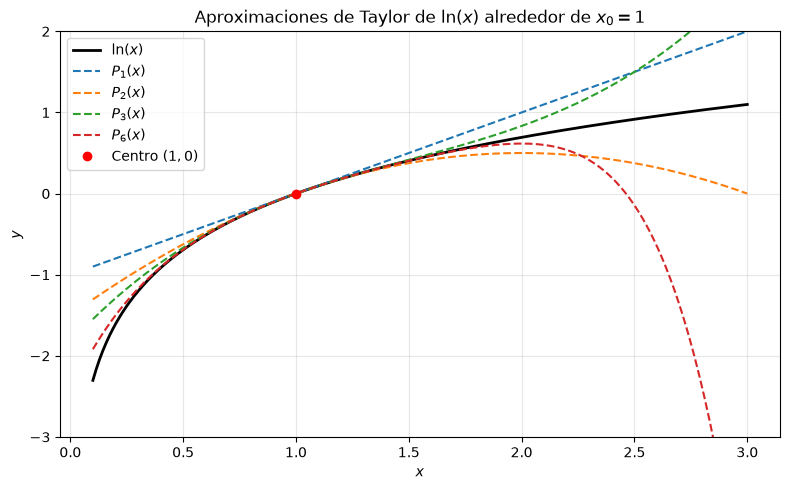

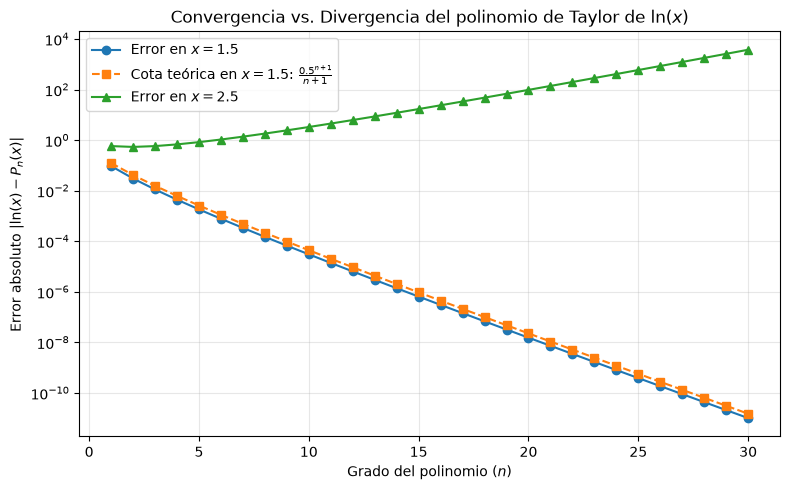

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def taylor_ln(x, n):
    """Polinomio de Taylor de grado n de ln(x) alrededor de x0 = 1."""
    suma = 0
    for k in range(1, n + 1):
        suma = suma + ((-1)**(k + 1)) * ((x - 1)**k) / k
    return suma

# 1. Verificación y cálculos numéricos
print(f"P3(1.5)  = {taylor_ln(1.5, 3):.6f}")
print(f"P10(1.5) = {taylor_ln(1.5, 10):.6f}")
print(f"P10(2.5) = {taylor_ln(2.5, 10):.6f}")

for n in range(1, 31):
    if abs(np.log(1.5) - taylor_ln(1.5, n)) < 1e-6:
        print(f"Menor grado n con error < 1e-6 en x=1.5: {n}")
        break

# 2. Gráfica 1: ln(x) y polinomios P1, P2, P3, P6 en [0.1, 3]
x_vals = np.linspace(0.1, 3, 400)

plt.figure(figsize=(8, 5))
plt.plot(x_vals, np.log(x_vals), 'k-', linewidth=2, label=r'$\ln(x)$')
for grado in [1, 2, 3, 6]:
    plt.plot(x_vals, taylor_ln(x_vals, grado), '--', label=f'$P_{grado}(x)$')

plt.plot(1, 0, 'ro', label='Centro $(1, 0)$')
plt.ylim(-3, 2)
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.title('Aproximaciones de Taylor de $\ln(x)$ alrededor de $x_0 = 1$')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 3. Gráfica 2: Error absoluto en escala semilogarítmica para n = 1..30
n_vals = np.arange(1, 31)
err_15 = [abs(np.log(1.5) - taylor_ln(1.5, n)) for n in n_vals]
err_25 = [abs(np.log(2.5) - taylor_ln(2.5, n)) for n in n_vals]
cota_15 = [(0.5**(n + 1)) / (n + 1) for n in n_vals]

plt.figure(figsize=(8, 5))
plt.semilogy(n_vals, err_15, 'o-', label=r'Error en $x = 1.5$')
plt.semilogy(n_vals, cota_15, 's--', label=r'Cota teórica en $x = 1.5$: $\frac{0.5^{n+1}}{n+1}$')
plt.semilogy(n_vals, err_25, '^-', label=r'Error en $x = 2.5$')

plt.xlabel('Grado del polinomio ($n$)')
plt.ylabel('Error absoluto $|\ln(x) - P_n(x)|$')
plt.title('Convergencia vs. Divergencia del polinomio de Taylor de $\ln(x)$')
plt.grid(True, which='both', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()